# 02 - Data processing

**Owner:** Member 1
**Task:** Turn the raw logs described in notebook 01 into the datasets every model uses: positive definition, repeated interactions, filtering, train/validation/test split and the unbiased test sets. Check the splits, describe the final training graphs and both test sets, and save the processed datasets for the team.
**Inputs:** raw files under `data/`, src/data/, src/inference/ (`evaluate`)
**Outputs:** data/processed/{kuairand,kuairec}_seed{0,1,2}.npz (not in git), results/02_data_stats.json, results/02_dataset_overview.csv, results/02_degree_distributions.png

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
import torch
import data
import inference

SEEDS = [0, 1, 2]
RESULTS_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "results"))
os.makedirs(RESULTS_DIR, exist_ok=True)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", None, "display.float_format", "{:,.3f}".format)

# 1. Summary of this section

The processing is done by `src/data/` and is identical for every model. Steps:

1. **Positive:** KuaiRand-Pure `is_click == 1`; KuaiRec `watch_ratio >= 2` in at least one play.
2. **Repeated interactions:** one positive per (user, video) pair.
3. **Filtering:** users with fewer than 2 positives cannot be split into train and test and are dropped; user and video ids are remapped to 0, 1, 2, ...
4. **Split of the biased logs, per user:** a random 20% of the user's positives go to `test`, then 10% of the rest to `val`, the remainder is `train`.
5. **Unbiased test:** positives from the unbiased part (KuaiRand: random log; KuaiRec: small matrix) of users and videos that are in the training graph, without pairs that are positive in the biased logs. On KuaiRec it is ranked among the block videos only (`unbiased_items`).

**Where the processed data is:** `data/processed/kuairand_seed{0,1,2}.npz` and `data/processed/kuairec_seed{0,1,2}.npz`, read with `data.load_processed(name, seed)` (section 6). They are not in git, like everything under `data/`.

# 2. From raw logs to positives
Only the columns needed for processing are loaded; notebook 01 describes the full files.

In [2]:
names = {"standard 04-09..04-21": data.KUAI_STANDARD[0], "standard 04-22..05-08": data.KUAI_STANDARD[1], "random 04-22..05-08": data.KUAI_RANDOM}
kuai_cols = ["user_id", "video_id", "is_rand", "is_click", "is_like", "long_view"]
logs = pd.concat([pd.read_csv(os.path.join(data.KUAI_DIR, f), usecols=kuai_cols) for f in names.values()], ignore_index=True)
logs["exposure"] = np.where(logs.is_rand == 1, "random", "standard")
std, rnd = logs[logs.exposure == "standard"], logs[logs.exposure == "random"]

types = {"user_id": "int32", "video_id": "int32", "watch_ratio": "float32"}
with zipfile.ZipFile(data.KUAIREC_ZIP) as z:
    rec = {m: pd.read_csv(z.open(data.KUAIREC_FILES + f"{m}_matrix.csv"), usecols=list(types), dtype=types) for m in ("big", "small")}
big, small = rec["big"], rec["small"]
pd.DataFrame({"KuaiRand standard exposures": [len(std)], "KuaiRand random exposures": [len(rnd)],
              "KuaiRec big-matrix plays": [len(big)], "KuaiRec small-matrix plays": [len(small)]}, index=["rows"]).T

,rows
KuaiRand standard exposures,1436609
KuaiRand random exposures,1186059
KuaiRec big-matrix plays,12530806
KuaiRec small-matrix plays,4676570


## 2.1 Positive definition
### KuaiRand-Pure: candidate feedback signals
The three signals frequent enough to define a positive (rates from notebook 01), and the dataset each would give.

In [3]:
CANDIDATES = ["is_click", "is_like", "long_view"]
by_exposure = {"standard": std, "random": rnd}
signal_rates = pd.DataFrame({k: df[CANDIDATES].mean() for k, df in by_exposure.items()})
signal_rates.loc["exposures"] = [len(std), len(rnd)]
signal_rates

,standard,random
is_click,0.460,0.176
is_like,0.018,0.005
long_view,0.332,0.085
exposures,"1,436,609.000","1,186,059.000"


In [4]:
by_signal = {s: data.stats(data.load("kuairand", seed=0, positive=s)) for s in CANDIDATES}
pd.DataFrame(by_signal).T.drop(columns="name")

,users,items,train,val,test,test_unbiased,density,cold_users,cold_items
is_click,25689,7218,466490,54223,131436,194539,0.003,0,122
is_like,3433,3518,15248,2112,5526,2349,0.001,0,408
long_view,24916,6863,336808,40451,95922,90782,0.002,0,159


### KuaiRec: watch-ratio threshold
What each threshold gives in the big matrix. `>= 1` would double the graph and make LightGCN about 7 times slower per epoch; `>= 2` keeps a size similar to KuaiRand-Pure.

In [5]:
rows = {}
for t in [1.0, 1.5, 2.0, 3.0]:
    p = big[big.watch_ratio >= t].drop_duplicates(["user_id", "video_id"])
    n_u, n_i = p.user_id.nunique(), p.video_id.nunique()
    rows[f">= {t:g}"] = dict(positive_pairs=len(p), users=n_u, videos=n_i, density=len(p) / (n_u * n_i), per_user=len(p) / n_u)
pd.DataFrame(rows).T

,positive_pairs,users,videos,density,per_user
>= 1,"3,731,826.000","7,176.000","10,719.000",0.049,520.043
>= 1.5,"1,689,080.000","7,175.000","10,674.000",0.022,235.412
>= 2,"846,414.000","7,175.000","10,611.000",0.011,117.967
>= 3,"312,145.000","6,973.000","8,833.000",0.005,44.765


## 2.2 Repeated interactions
KuaiRand: a user can be shown the same video more than once; we keep one positive per (user, video). KuaiRec: a user can play the same video more than once; the pair is positive if any play reaches the threshold.

In [6]:
duplicates = {}
for k, df in by_exposure.items():
    pos = df[df.is_click == 1]
    unique = len(pos.drop_duplicates(["user_id", "video_id"]))
    duplicates[k] = dict(exposures=len(df), repeated_exposures=int(df.duplicated(["user_id", "video_id"]).sum()),
                         clicks=len(pos), unique_click_pairs=unique, removed=len(pos) - unique,
                         removed_share=(len(pos) - unique) / len(pos))
pd.DataFrame(duplicates).T

,exposures,repeated_exposures,clicks,unique_click_pairs,removed,removed_share
standard,"1,436,609.000","61,609.000","660,342.000","653,051.000","7,291.000",0.011
random,"1,186,059.000",53.000,"208,934.000","208,934.000",0.000,0.000


In [7]:
pair_max = big.groupby(["user_id", "video_id"]).watch_ratio.agg(["size", "max", "min"])
repeated = pair_max[pair_max["size"] > 1]
pd.Series({"pairs": len(pair_max), "pairs played more than once": len(repeated),
           "positive by max, negative by min": int(((repeated["max"] >= 2) & (repeated["min"] < 2)).sum()),
           "positive pairs": int((pair_max["max"] >= 2).sum())}).to_frame("count")

,count
pairs,10300969
pairs played more than once,1841544
"positive by max, negative by min",103863
positive pairs,846414


## 2.3 Filtering and id remapping
A user needs at least 2 positives: one for training and one for testing. Users with a single positive are dropped, and the videos only they liked drop out with them. Then the unbiased positives are restricted to users and videos that are in the training graph (a model cannot score an unknown id), and pairs that are already positive in the biased logs are removed (they are known positives, not new information).

In [8]:
def filtering(users, items):
    pairs = pd.DataFrame({"user_id": users, "video_id": items}).drop_duplicates()
    per_user = pairs.groupby("user_id").size()
    kept = pairs[pairs.user_id.isin(per_user.index[per_user >= 2])]
    row = {"positive pairs": len(pairs), "users": pairs.user_id.nunique(), "users with 1 positive (dropped)": int((per_user < 2).sum()),
           "videos": pairs.video_id.nunique(), "pairs kept": len(kept), "users kept": kept.user_id.nunique(), "videos kept": kept.video_id.nunique()}
    return row, kept

def unbiased_filtering(users, items, kept):
    pairs = pd.DataFrame({"user_id": users, "video_id": items}).drop_duplicates()
    known = pairs[pairs.user_id.isin(set(kept.user_id)) & pairs.video_id.isin(set(kept.video_id))]
    new = known[~pd.MultiIndex.from_frame(known).isin(pd.MultiIndex.from_frame(kept))]
    return {"positive pairs": len(pairs), "of users and videos in the graph": len(known),
            "not positive in the biased logs (final)": len(new), "users (final)": new.user_id.nunique()}

std_pos, rnd_pos = std[std.is_click == 1], rnd[rnd.is_click == 1]
big_pos, small_pos = big[big.watch_ratio >= 2], small[small.watch_ratio >= 2]
rand_row, rand_kept = filtering(std_pos.user_id, std_pos.video_id)
rec_row, rec_kept = filtering(big_pos.user_id, big_pos.video_id)
filter_biased = pd.DataFrame({"KuaiRand-Pure": rand_row, "KuaiRec": rec_row}).T
filter_unbiased = pd.DataFrame({"KuaiRand-Pure": unbiased_filtering(rnd_pos.user_id, rnd_pos.video_id, rand_kept),
                                "KuaiRec": unbiased_filtering(small_pos.user_id, small_pos.video_id, rec_kept)}).T
print("Biased logs (train / val / test)")
display(filter_biased)
print("Unbiased part (test_unbiased)")
filter_unbiased

Biased logs (train / val / test)


,positive pairs,users,users with 1 positive (dropped),videos,pairs kept,users kept,videos kept
KuaiRand-Pure,653051,26591,902,7218,652149,25689,7218
KuaiRec,846414,7175,2,10611,846412,7173,10611


Unbiased part (test_unbiased)


,positive pairs,of users and videos in the graph,not positive in the biased logs (final),users (final)
KuaiRand-Pure,208934,194544,194539,21515
KuaiRec,217229,216727,216727,1408


## 2.4 Train / validation / test split
For each user, a random 20% of the biased positives go to `test` (at least one), then 10% of the remaining items go to `val` (at least one if the user has 3 or more), and the rest is `train`. The split is random rather than by time: both models see the same split, and the random log covers only the second half of the period, so a time split would leave few unbiased test users. Cold items are test items with no training interaction.

In [9]:
datasets = {"kuairand": data.load("kuairand", seed=0), "kuairec": data.load("kuairec", seed=0)}
stats = {k: data.stats(ds) for k, ds in datasets.items()}
for key, filt in [("kuairand", "KuaiRand-Pure"), ("kuairec", "KuaiRec")]:
    assert stats[key]["users"] == filter_biased.loc[filt, "users kept"] and stats[key]["items"] == filter_biased.loc[filt, "videos kept"]
    assert stats[key]["test_unbiased"] == filter_unbiased.loc[filt, "not positive in the biased logs (final)"]
table = pd.DataFrame(stats).T.drop(columns="name")
table["density"] = table["density"].astype(float).map("{:.3%}".format)
table

,users,items,train,val,test,test_unbiased,density,cold_users,cold_items
kuairand,25689,7218,466490,54223,131436,194539,0.252%,0,122
kuairec,7173,10611,609375,67773,169264,216727,0.801%,0,413


The split is random per user, so the sizes must not depend on the seed.

In [10]:
for name in datasets:
    sizes = {s: [data.stats(data.load(name, seed=s))[c] for c in ("train", "val", "test", "test_unbiased")] for s in SEEDS}
    print(name, sizes)
    assert len({tuple(v) for v in sizes.values()}) == 1

kuairand {0: [466490, 54223, 131436, 194539], 1: [466490, 54223, 131436, 194539], 2: [466490, 54223, 131436, 194539]}


kuairec {0: [609375, 67773, 169264, 216727], 1: [609375, 67773, 169264, 216727], 2: [609375, 67773, 169264, 216727]}


# 3. Split checks
No pair may appear in two splits, every test user needs training items, and the unbiased test may not contain any pair that is positive in the biased data.

In [11]:
def pairs(split):
    return {(u, int(i)) for u, v in split.items() for i in v}

for key, ds in datasets.items():
    tr, va, te, tu = (pairs(ds[s]) for s in ("train", "val", "test", "test_unbiased"))
    assert not (tr & va) and not (tr & te) and not (va & te) and not (tu & (tr | va | te))
    assert all(len(ds["train"][u]) > 0 for u in list(ds["test"]) + list(ds["test_unbiased"]))
    print(f"{key}: splits disjoint; {len(ds['test']):,} test users and {len(ds['test_unbiased']):,} unbiased-test users, all with training items")
items = np.array([i for _, i in pairs(datasets["kuairec"]["test_unbiased"])])
assert np.isin(items, datasets["kuairec"]["unbiased_items"]).all()
print("kuairec: every unbiased test item is a block video")

kuairand: splits disjoint; 25,689 test users and 21,515 unbiased-test users, all with training items


kuairec: splits disjoint; 7,173 test users and 1,408 unbiased-test users, all with training items


kuairec: every unbiased test item is a block video


# 4. The final training graphs
## 4.1 Degree distributions
Degree = number of training positives of a user or an item.

In [12]:
def gini(x):
    x = np.sort(x.astype(float))
    n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))

def degree_summary(deg):
    top = np.sort(deg)[::-1][: max(1, len(deg) // 100)]
    return dict(min=int(deg.min()), median=float(np.median(deg)), mean=float(deg.mean()), max=int(deg.max()),
                share_below_10=float((deg < 10).mean()), gini=gini(deg), top1pct_share=float(top.sum() / deg.sum()))

main = {"KuaiRand-Pure": datasets["kuairand"], "KuaiRec": datasets["kuairec"]}
degree_stats = {}
for name, ds in main.items():
    user_deg, item_deg = data.degrees(ds)
    degree_stats[name] = dict(user=degree_summary(user_deg), item=degree_summary(item_deg))
pd.DataFrame({(n, side): s for n, d in degree_stats.items() for side, s in d.items()}).T.round(3)

min  median   mean       max  share_below_10  gini  top1pct_share
KuaiRand-Pure user 1.000  13.000 18.159   169.000           0.383 0.463          0.049
              item 0.000  15.000 64.629 4,251.000           0.411 0.759          0.205
KuaiRec       user 1.000  63.000 84.954   722.000           0.033 0.442          0.048
              item 0.000  10.000 57.429 1,859.000           0.500 0.748          0.135

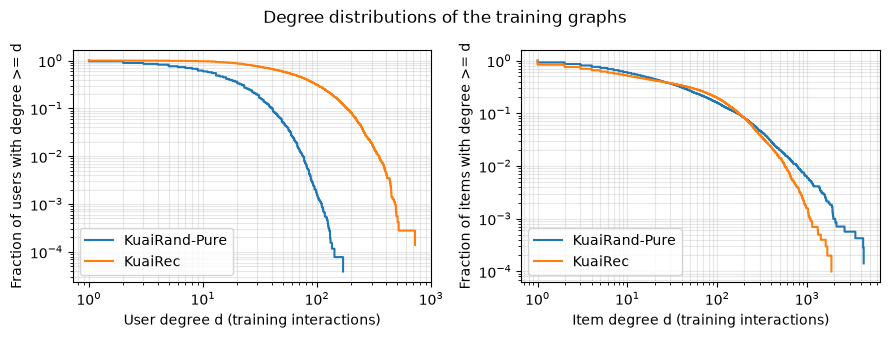

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for name, ds in main.items():
    for ax, deg in zip(axes, data.degrees(ds)):
        d = np.sort(deg[deg > 0])
        ax.step(d, 1 - np.arange(len(d)) / len(d), where="post", label=name)
for ax, side in zip(axes, ["User", "Item"]):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"{side} degree d (training interactions)")
    ax.set_ylabel(f"Fraction of {side.lower()}s with degree >= d")
    ax.grid(alpha=0.3, which="both"); ax.legend()
fig.suptitle("Degree distributions of the training graphs")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "02_degree_distributions.png"), dpi=200, metadata={"Software": None})
plt.show()

## 4.2 The two datasets side by side
Raw data (notebook 01) next to the graph `src/data/` builds from it (seed 0).

In [14]:

def graph_rows(ds, s):
    return {"Users / items in the graph": f"{s['users']:,} / {s['items']:,}",
            "Train / val / test positives": f"{s['train']:,} / {s['val']:,} / {s['test']:,}",
            "Training density": f"{s['density']:.2%}", "Training positives per user": f"{s['train'] / s['users']:.1f}",
            "Unbiased test": f"{s['test_unbiased']:,} positives, {len(ds['test_unbiased']):,} users"}

rec_pos = big[big.watch_ratio >= 2].drop_duplicates(["user_id", "video_id"])
comparison = pd.DataFrame({
    "KuaiRand-Pure": {"Platform": "Kuaishou short videos", "Collected": "9 Apr - 8 May 2022", "Feedback": "Click, like, long view, ... per exposure",
                      "Positive": "is_click == 1", "Biased logs": f"{len(std):,} recommender-chosen exposures",
                      "Unbiased part": f"{len(rnd):,} randomly exposed videos", "How the unbiased part removes bias": "Test videos chosen at random",
                      "Raw users / videos": f"{logs.user_id.nunique():,} / {logs.video_id.nunique():,}",
                      **graph_rows(datasets["kuairand"], stats["kuairand"]), "Unbiased ranking over": "all items"},
    "KuaiRec": {"Platform": "Kuaishou short videos", "Collected": "5 Jul - 5 Sep 2020", "Feedback": "Watch ratio per play",
                "Positive": "watch_ratio >= 2 (any play)", "Biased logs": f"{len(big):,} plays (big matrix)",
                "Unbiased part": f"{len(small):,} plays (small matrix, 99.6% filled)", "How the unbiased part removes bias": "Every user saw every block video",
                "Raw users / videos": f"{big.user_id.nunique():,} / {big.video_id.nunique():,}",
                **graph_rows(datasets["kuairec"], stats["kuairec"]), "Unbiased ranking over": f"{len(datasets['kuairec']['unbiased_items']):,} block videos"}})
comparison.to_csv(os.path.join(RESULTS_DIR, "02_dataset_overview.csv"))
comparison

,KuaiRand-Pure,KuaiRec
Platform,Kuaishou short videos,Kuaishou short videos
Collected,9 Apr - 8 May 2022,5 Jul - 5 Sep 2020
Feedback,"Click, like, long view, ... per exposure",Watch ratio per play
Positive,is_click == 1,watch_ratio >= 2 (any play)
Biased logs,"1,436,609 recommender-chosen exposures","12,530,806 plays (big matrix)"
Unbiased part,"1,186,059 randomly exposed videos","4,676,570 plays (small matrix, 99.6% filled)"
How the unbiased part removes bias,Test videos chosen at random,Every user saw every block video
Raw users / videos,"27,285 / 7,583","7,176 / 10,728"
Users / items in the graph,"25,689 / 7,218","7,173 / 10,611"
Train / val / test positives,"466,490 / 54,223 / 131,436","609,375 / 67,773 / 169,264"


# 5. Biased vs. unbiased test
How popular are the test positives? Popularity of an item = its training degree. Then a most-popular baseline (recommend the items with the highest training degree to everyone) on both tests, and the best possible Recall@20 (a user with more than 20 positives cannot reach recall 1).

In [15]:
class MostPopular:
    """Scores every item by its training degree, the same for every user."""
    def __init__(self, ds):
        self.item_deg = torch.tensor(data.degrees(ds)[1], dtype=torch.float32)[:, None]
        self.n_users = ds["n_users"]
    def eval(self):
        pass
    def embeddings(self):
        return torch.ones(self.n_users, 1), self.item_deg

def test_popularity(ds, split):
    _, item_deg = data.degrees(ds)
    targets = np.concatenate(list(ds[split].values()))
    head = np.argsort(-item_deg)[: ds["n_items"] // 10]
    best = np.mean([min(len(v), 20) / len(v) for v in ds[split].values() if len(v)])
    return dict(users=len(ds[split]), positives=len(targets), mean_item_degree=float(item_deg[targets].mean()),
                share_in_top10pct_items=float(np.isin(targets, head).mean()), best_possible_recall=float(best))

split_compare = {}
for key, ds in datasets.items():
    for split, mask in [("test", ("train", "val")), ("test_unbiased", ("train", "val", "test"))]:
        m, _, _ = inference.evaluate(MostPopular(ds), ds, split, mask_splits=mask)
        split_compare[(key, split)] = {**test_popularity(ds, split), "most_popular_recall": m["recall"], "most_popular_ndcg": m["ndcg"]}
pd.DataFrame(split_compare).T

users   positives  mean_item_degree  share_in_top10pct_items  best_possible_recall  most_popular_recall  most_popular_ndcg
kuairand test          25,689.000 131,436.000           530.306                    0.630                 0.998                0.114              0.076
         test_unbiased 21,515.000 194,539.000            88.780                    0.144                 0.957                0.007              0.005
kuairec  test           7,173.000 169,264.000           282.036                    0.558                 0.815                0.074              0.088
         test_unbiased  1,408.000 216,727.000           297.043                    0.551                 0.318                0.150              0.541

# 6. Save
## 6.1 Statistics

In [16]:
out = dict(seed=0, positive=dict(kuairand="is_click == 1", kuairec="watch_ratio >= 2 (any play)"),
           datasets=stats, degrees=degree_stats, kuairand_signal_rates=signal_rates.to_dict(), kuairand_by_signal=by_signal,
           kuairand_duplicates=duplicates, filtering=dict(biased=filter_biased.to_dict(), unbiased=filter_unbiased.to_dict()), split_compare={f"{k}|{s}": v for (k, s), v in split_compare.items()})
with open(os.path.join(RESULTS_DIR, "02_data_stats.json"), "w") as f:
    json.dump(out, f, indent=1, default=float)
print("saved", sorted(os.listdir(RESULTS_DIR)))

saved ['.gitkeep', '01_data_stats.json', '01_dataset_overview.csv', '01_degree_distributions.png', '01_kuairand_daily.png', '01_kuairand_per_video.png', '01_kuairec_watch_ratio.png', '02_data_stats.json', '02_dataset_overview.csv', '02_degree_distributions.png']


## 6.2 Processed datasets for the team
Every dataset for seeds 0, 1 and 2 is written to `data/processed/` and read back; the copy must equal what `data.load` builds, including the order of users and items, so a model trained on either gets the same batches.

In [17]:
files = {}
for name in datasets:
    for seed in SEEDS:
        ds = datasets[name] if seed == 0 else data.load(name, seed=seed)
        path = data.save_processed(ds, name, seed)
        back = data.load_processed(name, seed)
        assert back.keys() == ds.keys() and all(back[k] == ds[k] for k in ("name", "n_users", "n_items"))
        for s in ("train", "val", "test", "test_unbiased"):
            assert list(back[s]) == list(ds[s]) and all(np.array_equal(back[s][u], ds[s][u]) for u in ds[s])
        if "unbiased_items" in ds:
            assert np.array_equal(back["unbiased_items"], ds["unbiased_items"])
        files[os.path.relpath(path, os.path.join(data.DATA_DIR, ".."))] = dict(users=ds["n_users"], items=ds["n_items"],
                                                                               train=sum(len(v) for v in ds["train"].values()),
                                                                               size_mb=os.path.getsize(path) / 1e6)
pd.DataFrame(files).T

,users,items,train,size_mb
data\processed\kuairand_seed0.npz,"25,689.000","7,218.000","466,490.000",2.108
data\processed\kuairand_seed1.npz,"25,689.000","7,218.000","466,490.000",2.109
data\processed\kuairand_seed2.npz,"25,689.000","7,218.000","466,490.000",2.108
data\processed\kuairec_seed0.npz,"7,173.000","10,611.000","609,375.000",2.478
data\processed\kuairec_seed1.npz,"7,173.000","10,611.000","609,375.000",2.478
data\processed\kuairec_seed2.npz,"7,173.000","10,611.000","609,375.000",2.479


## 6.3 How to use the processed data
```python
import data
ds = data.load_processed("kuairand", seed=0)    # or "kuairec"; seeds 0, 1, 2
```
`ds` is the same dictionary as `data.load("kuairand", seed=0)`: `name`, `n_users`, `n_items`, `train`, `val`, `test`, `test_unbiased` (each `{user: np.array(items)}`) and, for KuaiRec, `unbiased_items`. Reading it takes about a second, against up to half a minute for `data.load`. The files are not in git: run this notebook once with the raw data in `data/`, or copy the `.npz` files into `data/processed/`.

In [18]:
ds = data.load_processed("kuairec", seed=0)
print({k: (type(v).__name__, len(v)) if hasattr(v, "__len__") and not isinstance(v, str) else v for k, v in ds.items()})
u = next(iter(ds["test_unbiased"]))
print(f"user {u}: {len(ds['train'][u])} train items, {len(ds['test'][u])} test items, {len(ds['test_unbiased'][u])} unbiased test items")

{'name': 'KuaiRec (watch_ratio >= 2)', 'n_users': 7173, 'n_items': 10611, 'train': ('dict', 7173), 'val': ('dict', 7173), 'test': ('dict', 7173), 'test_unbiased': ('dict', 1408), 'unbiased_items': ('ndarray', 3326)}
user 14: 27 train items, 7 test items, 179 unbiased test items


## Summary

- **Both datasets come from the same platform** (Kuaishou short videos), so differences between them are not a change of domain.
- **KuaiRand-Pure** is very sparse (0.25% training density, 18 positives per user) and its item popularity is highly concentrated. Its unbiased test uses randomly exposed videos, which are mostly unpopular: only 14% of unbiased positives fall on the 10% most popular items, against 63% of the biased test positives. A most-popular baseline drops from Recall@20 0.114 to 0.007.
- **KuaiRec** is denser (0.80%, 85 positives per user) and its unbiased test is a fully observed block of videos that are themselves popular. Popularity still pays there: the most-popular baseline reaches NDCG@20 of about 0.54 on the unbiased test. Recall@20 is capped (best possible about 0.32) because users have about 150 unbiased positives each, so NDCG@20 and the margin over most-popular are the numbers to compare.
- The two unbiased tests therefore remove different biases: KuaiRand's removes the recommender's choice of *which* videos are shown, KuaiRec's removes *missing* feedback on a fixed popular block. A model's advantage that survives both is a strong result; one that survives only KuaiRec's is likely driven by popularity.
- **KuaiRec's positive definition favours short videos:** 11% of plays of videos under 10 s reach a watch ratio of 2, against 0.2% for videos over 60 s. Under 10 s videos are 54% of all plays.